# Train T

This tutorial uses the paired 5-dimensional RNA and ATAC PCA representations produced from the [scMultiSim R workflow](generate_data.R) and used by `TraInf/Synthetic/data/MLPVisual.ipynb`. The numeric archives download automatically when they are not present in a local COATI checkout.

No pretrained map is loaded. We first assemble paired AnnData, then fit and independently test $T:\mathrm{RNA}\rightarrow\mathrm{ATAC}$.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib
import json
import uuid

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from threadpoolctl import threadpool_limits

import coati as ct
from coati.maps import load_map, train_map

%matplotlib inline
threadpool_limits(limits=1)
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

TIME_KEYS = ("time1", "time2", "time3", "time4")
TIME_VALUES = np.arange(4, dtype=float)
DATA_BASE_URL = "https://raw.githubusercontent.com/shankswang953/COATI/main/examples/data/scmultisim"
DATA_SHA256 = {
    "all_time_scRNA_pca.npz": "6909f00854f10eaa2a8e2f287fb04659583baab3318392e1fb4b5e0ff40f15a6",
    "all_time_scATAC_pca.npz": "57f2b3c6d717906bea4b1e97817173dc25d1ff1d5cde44c45011609c7f298a38",
}
cache_dir = Path("outputs") / "scmultisim-data"
run_dir = Path("outputs") / ("scmultisim-map-" + uuid.uuid4().hex[:8])
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Map training device:", device)

Map training device: mps


## Prepare paired AnnData

Rows are paired within each time point. RNA is stored in `obsm["X_pca"]`, ATAC in `obsm["X_atac"]`, and canonical `time`, `celltype`, and `barcode` fields are created. The source archives have no cell-type annotations, so the label is explicitly `"unknown"`.

In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def obtain_data(filename):
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidate = parent / "examples" / "data" / "scmultisim" / filename
        if candidate.is_file():
            path = candidate
            break
    else:
        cache_dir.mkdir(parents=True, exist_ok=True)
        path = cache_dir / filename
        if not path.is_file():
            print("Downloading", filename)
            urlretrieve(f"{DATA_BASE_URL}/{filename}", path)
    if sha256(path) != DATA_SHA256[filename]:
        raise RuntimeError(f"Checksum mismatch for {path}")
    return path


with np.load(obtain_data("all_time_scRNA_pca.npz"), allow_pickle=False) as archive:
    rna = [np.asarray(archive[key], dtype=np.float32) for key in TIME_KEYS]
with np.load(obtain_data("all_time_scATAC_pca.npz"), allow_pickle=False) as archive:
    atac = [np.asarray(archive[key], dtype=np.float32) for key in TIME_KEYS]

for key, x, y in zip(TIME_KEYS, rna, atac):
    if x.shape[0] != y.shape[0] or x.shape[1:] != y.shape[1:] or x.shape[1] != 5:
        raise ValueError(f"Unexpected paired shapes at {key}: RNA {x.shape}, ATAC {y.shape}")

barcodes = np.concatenate([
    [f"scmultisim-{key}-{index:05d}" for index in range(len(x))]
    for key, x in zip(TIME_KEYS, rna)
])
stages = np.concatenate([np.repeat(key, len(x)) for key, x in zip(TIME_KEYS, rna)])

cells = ct.prepare_anndata(
    rna, time=TIME_VALUES, celltype=np.repeat("unknown", len(barcodes)),
    barcode=barcodes, use_rep="X_pca",
    secondary=atac, secondary_key="X_atac", warn=False,
)
cells.obs["stage"] = pd.Categorical(stages, categories=TIME_KEYS, ordered=True)

assert cells.obs_names.is_unique
assert cells.obsm["X_pca"].shape == cells.obsm["X_atac"].shape == (10000, 5)
print(cells)
cells.obs.groupby("stage", observed=True).size().rename("cells").to_frame()

AnnData object with n_obs × n_vars = 10000 × 5
    obs: 'time', 'celltype', 'barcode', 'stage'
    uns: 'coati_input'
    obsm: 'X_pca', 'X_atac'


,cells
stage,
time1,2006
time2,2001
time3,3008
time4,2985


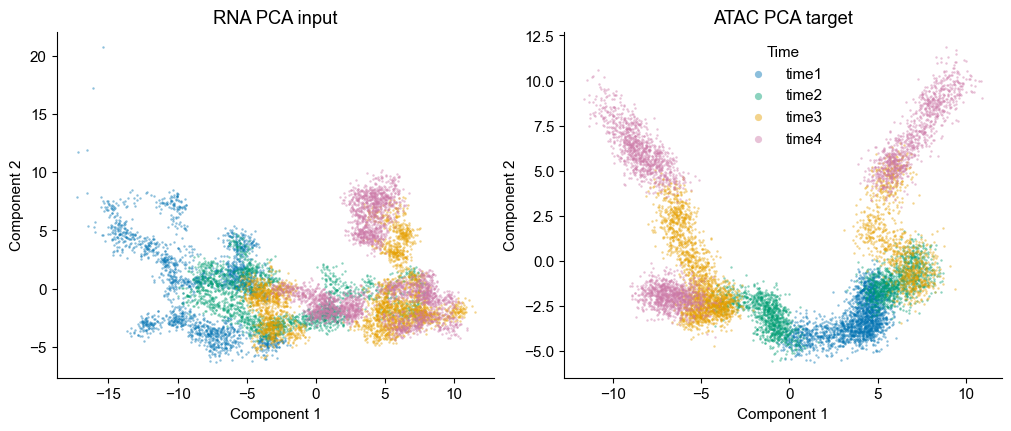

In [3]:
stage_palette = dict(zip(TIME_KEYS, ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
for ax, values, title in zip(
    axes, (cells.obsm["X_pca"], cells.obsm["X_atac"]),
    ("RNA PCA input", "ATAC PCA target"),
):
    for stage in TIME_KEYS:
        mask = cells.obs["stage"].to_numpy() == stage
        ax.scatter(*values[mask, :2].T, s=3, alpha=.45, linewidths=0,
                   color=stage_palette[stage], label=stage, rasterized=True)
    ax.set(title=title, xlabel="Component 1", ylabel="Component 2")
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, title="Time", markerscale=3)
plt.show()

## Fit an MLP map

Twenty percent of every time point is reserved as an independent paired test set. COATI makes another disjoint training/validation split inside the remaining reference cells and selects the checkpoint by validation loss.

The original experiment used four hidden layers of width 512. `hidden_dim=512, n_layers=5` keeps the same input–four-hidden–output depth while COATI adds feature standardization, early stopping, checkpoint reload support, and per-stage diagnostics.

In [4]:
rng = np.random.default_rng(17)
times = cells.obs["time"].to_numpy()
reference_parts, test_parts = [], []
for time in TIME_VALUES:
    rows = rng.permutation(np.flatnonzero(times == time))
    n_test = round(.20 * len(rows))
    test_parts.append(rows[:n_test])
    reference_parts.append(rows[n_test:])

reference_rows = np.sort(np.concatenate(reference_parts))
test_rows = np.sort(np.concatenate(test_parts))
assert not np.intersect1d(reference_rows, test_rows).size
assert len(reference_rows) + len(test_rows) == cells.n_obs

reference_cells = cells[reference_rows].copy()
paired = ct.TemporalData.from_anndata(
    reference_cells, obsm_key="X_pca", secondary_obsm_key="X_atac"
)
print("Reference / independent test:", len(reference_rows), "/", len(test_rows))

Reference / independent test: 8000 / 2000


In [5]:
map_config = ct.MapConfig(
    hidden_dim=512, n_layers=5,
    epochs=400, batch_size=1024, lr=2e-3, weight_decay=0.0,
    validation_fraction=.20, patience=50,
    eval_samples=256, eval_repeats=5,
)
T, map_report = train_map(
    paired, kind="mlp", config=map_config,
    directory=run_dir / "map", device=device, seed=0, verbose=True,
)
print("Best epoch:", map_report["best_epoch"],
      "| completed:", map_report["epochs_completed"],
      "| validation:", map_report["status"])
pd.DataFrame(map_report["stages"])[
    ["label", "train_cells", "validation_cells",
     "paired_rmse", "normalized_mse", "sinkhorn_ratio"]
].round(4)

[COATI map] Epoch 1/400, standardized validation MSE 0.316826.


[COATI map] Epoch 25/400, standardized validation MSE 0.0647232.


[COATI map] Epoch 50/400, standardized validation MSE 0.0575639.


[COATI map] Epoch 75/400, standardized validation MSE 0.0564935.


[COATI map] Epoch 100/400, standardized validation MSE 0.0537541.


[COATI map] Epoch 125/400, standardized validation MSE 0.0544264.


[COATI map] Epoch 150/400, standardized validation MSE 0.0546661.


[COATI map] Epoch 175/400, standardized validation MSE 0.0565834.


Best epoch: 137 | completed: 187 | validation: passed


,label,train_cells,validation_cells,paired_rmse,normalized_mse,sinkhorn_ratio
0,0.0,1284,321,0.6568,0.1633,0.7605
1,1.0,1281,320,0.6787,0.0704,0.7608
2,2.0,1925,481,0.6811,0.0476,0.5193
3,3.0,1910,478,0.7933,0.0306,0.5038


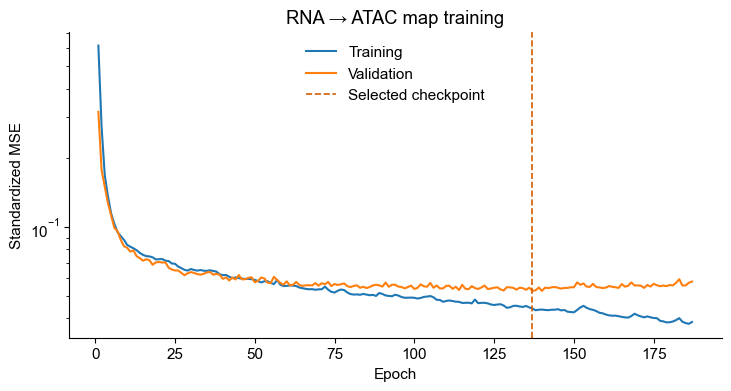

In [6]:
history = pd.read_json(run_dir / "map" / "history.json")
fig, ax = plt.subplots(figsize=(7.2, 3.8), layout="constrained")
ax.plot(history["epoch"], history["train_standardized_mse"], label="Training")
ax.plot(history["epoch"], history["validation_standardized_mse"], label="Validation")
ax.axvline(map_report["best_epoch"], color="#D55E00", linestyle="--",
           linewidth=1.2, label="Selected checkpoint")
ax.set(xlabel="Epoch", ylabel="Standardized MSE",
       title="RNA → ATAC map training", yscale="log")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Inspect T on unseen paired cells

The baseline predicts the corresponding reference-stage mean. Real and mapped test cells are shown directly in the same ATAC PCA coordinates, so the display adds no embedding fit or transformation.

In [7]:
x, y = cells.obsm["X_pca"], cells.obsm["X_atac"]

def map_points(model, points, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return np.concatenate([
            model(torch.as_tensor(points[start:start + batch_size],
                                  dtype=torch.float32, device=device)).cpu().numpy()
            for start in range(0, len(points), batch_size)
        ])


predicted = map_points(T, x[test_rows])
restored = load_map(run_dir / "map" / "model.pt", device=device)
np.testing.assert_array_equal(predicted, map_points(restored, x[test_rows]))

rows = []
for key, time in zip(TIME_KEYS, TIME_VALUES):
    test_mask = times[test_rows] == time
    ref_mask = times[reference_rows] == time
    truth, estimate = y[test_rows][test_mask], predicted[test_mask]
    baseline = y[reference_rows][ref_mask].mean(0)
    mse = float(np.mean((estimate - truth) ** 2))
    baseline_mse = float(np.mean((baseline - truth) ** 2))
    rows.append({"stage": key, "test_pairs": int(test_mask.sum()),
                 "paired_rmse": np.sqrt(mse),
                 "normalized_mse": mse / baseline_mse})

test_quality = pd.DataFrame(rows).set_index("stage")
display(test_quality.round(4))
print("Overall paired RMSE:", f"{np.sqrt(np.mean((predicted-y[test_rows])**2)):.4f}")
print("Exact checkpoint reload: passed")

,test_pairs,paired_rmse,normalized_mse
stage,,,
time1,401,0.6592,0.1733
time2,400,0.6906,0.0758
time3,602,0.7109,0.0498
time4,597,0.8021,0.0309


Overall paired RMSE: 0.7257
Exact checkpoint reload: passed


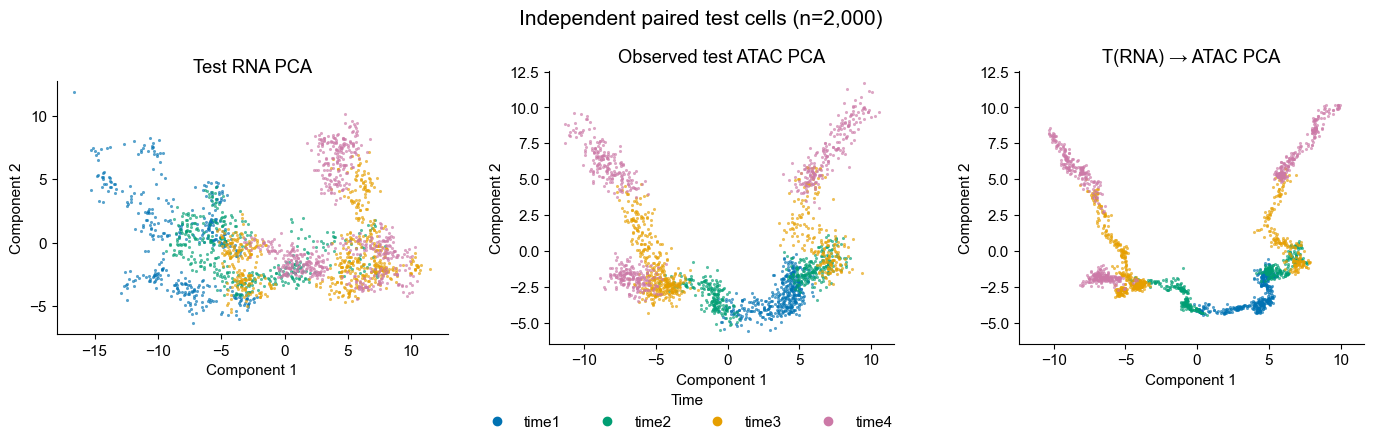

In [8]:
coordinates = [x[test_rows, :2], y[test_rows, :2], predicted[:, :2]]
titles = ["Test RNA PCA", "Observed test ATAC PCA", "T(RNA) → ATAC PCA"]
test_stages = cells.obs["stage"].astype(str).to_numpy()[test_rows]
atac_limits = np.vstack(coordinates[1:])
low, high = atac_limits.min(0), atac_limits.max(0)
pad = .05 * np.maximum(high-low, 1.)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for panel, (ax, points, title) in enumerate(zip(axes, coordinates, titles)):
    for stage in TIME_KEYS:
        mask = test_stages == stage
        ax.scatter(*points[mask].T, s=5, alpha=.65, linewidths=0,
                   color=stage_palette[stage], rasterized=True)
    ax.set(title=title, xlabel="Component 1", ylabel="Component 2")
    ax.set_aspect("equal", adjustable="box")
    ax.spines[["top", "right"]].set_visible(False)
    if panel:
        ax.set(xlim=(low[0]-pad[0], high[0]+pad[0]),
               ylim=(low[1]-pad[1], high[1]+pad[1]))
handles = [Line2D([], [], marker="o", linestyle="", color=stage_palette[s],
                  label=s, markersize=6) for s in TIME_KEYS]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, title="Time")
fig.suptitle(f"Independent paired test cells (n={len(test_rows):,})", fontsize=15, y=.98)
fig.subplots_adjust(left=.04, right=.99, bottom=.22, top=.84, wspace=.20)
plt.show()

In [9]:
summary = {
    "dataset": "scMultiSim",
    "source": "R-generated paired RNA and ATAC; prepared 5D PCA views from MLPVisual.ipynb",
    "reference_cells": int(len(reference_rows)),
    "independent_test_cells": int(len(test_rows)),
    "map_kind": "mlp",
    "map_config": map_config.to_dict(),
    "map_report": map_report,
    "independent_test": test_quality.reset_index().to_dict(orient="records"),
    "exact_checkpoint_reload": True,
    "source_sha256": DATA_SHA256,
}
(run_dir / "independent_test_report.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Saved map and reports:", run_dir.resolve())

Saved map and reports: /Users/jingfeng/local/project/COATI/notebooks/scMultisim/outputs/scmultisim-map-e5de83b1
